<a href="https://colab.research.google.com/github/PavelShershov/Machine_Learning/blob/main/%D0%A8%D0%B5%D1%80%D1%88%D0%BE%D0%B2_%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%D0%B2%D0%B0%D1%80%D0%B8%D0%B0%D0%BD%D1%82_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа "Изучение методов визуализации данных и статистического анализа с применением языка Python"

Вариант 1. Успеваемость школьников
student-mat.csv · Один учащийся курса математики.
X — G2, оценка за второй период. Y — G3, итоговая оценка (обе от 0 до 20).
Сгруппируйте по школе school.
Вычислите изменение оценки как G3 − G2. Сохраните нулевые оценки. Для каждой
школы найдите долю учеников, у которых результат снизился как минимум на два балла.
Исследовательский вопрос. Насколько часто итоговая оценка существенно ниже
предыдущей? Установите, видны ли такие случаи при сравнении одних только школьных
средних.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import iqr, spearmanr

from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

df.head()

Saving student-mat.csv to student-mat.csv


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 1. Подготовьте таблицу в pandas

### 1.1. Первичный просмотр данных

In [2]:
print('Размер таблицы:', df.shape)

df.info()

print('Пропуски по столбцам:')
print(df.isna().sum())

print('Всего пропусков:', df.isna().sum().sum())

print('Полных дубликатов:', df.duplicated().sum())

Размер таблицы: (395, 33)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null

### 1.2. Отбор необходимых столбцов

In [3]:
rows_before = len(df)

data = df[['school', 'G2', 'G3']].copy()

data = data.dropna(subset=['school', 'G2', 'G3'])

rows_after = len(data)

print('Количество записей до отбора:', rows_before)
print('Количество записей после отбора:', rows_after)
print('Исключено записей:', rows_before - rows_after)

print('Нулевых оценок G2:', (data['G2'] == 0).sum())
print('Нулевых оценок G3:', (data['G3'] == 0).sum())

print('Количество учащихся по школам:')
print(data['school'].value_counts())

Количество записей до отбора: 395
Количество записей после отбора: 395
Исключено записей: 0
Нулевых оценок G2: 13
Нулевых оценок G3: 38
Количество учащихся по школам:
school
GP    349
MS     46
Name: count, dtype: int64


**Обоснование отбора:** оставлены столбцы `school`, `G2` и `G3`, поскольку они нужны для сравнения оценок по школам и расчёта их изменения. Нулевые оценки сохранены, так как это значения оценок, а не пропуски. Одинаковые оценки у разных учащихся не считаются дубликатами.

### 1.3. Создание новых признаков

In [4]:
data['grade_change'] = data['G3'] - data['G2']

data['decrease_2plus'] = data['grade_change'] <= -2

data[['school', 'G2', 'G3', 'grade_change', 'decrease_2plus']].head(10)

,school,G2,G3,grade_change,decrease_2plus
0,GP,6,6,0,False
1,GP,5,6,1,False
2,GP,8,10,2,False
3,GP,14,15,1,False
4,GP,10,10,0,False
5,GP,15,15,0,False
6,GP,12,11,-1,False
7,GP,5,6,1,False
8,GP,18,19,1,False
9,GP,15,15,0,False


## 2. Получите сводку и проверьте вычисления

### 2.1. Функция для групповой статистики

In [5]:
def make_summary(table, value_column, group_column):
    grouped = table.groupby(group_column)[value_column]

    result = grouped.agg(['count', 'mean', 'median'])
    result['q1'] = grouped.quantile(0.25)
    result['q3'] = grouped.quantile(0.75)

    return result[['count', 'mean', 'median', 'q1', 'q3']]


summary_G2 = make_summary(data, 'G2', 'school')
print('Сводка по оценке G2:')
print(summary_G2.round(2))

summary_G3 = make_summary(data, 'G3', 'school')
print('Сводка по итоговой оценке G3:')
print(summary_G3.round(2))

Сводка по оценке G2:
        count   mean  median   q1     q3
school                                  
GP        349  10.78    11.0  9.0  13.00
MS         46  10.20    10.0  8.0  12.75
Сводка по итоговой оценке G3:
        count   mean  median   q1     q3
school                                  
GP        349  10.49    11.0  8.0  14.00
MS         46   9.85    10.0  8.0  12.75


### 2.2. Групповой показатель из варианта

In [6]:
school_summary = data.groupby('school').agg(
    students=('G3', 'count'),
    mean_G2=('G2', 'mean'),
    mean_G3=('G3', 'mean'),
    mean_change=('grade_change', 'mean'),
    decrease_count=('decrease_2plus', 'sum'),
    decrease_share=('decrease_2plus', 'mean')
)

school_summary['decrease_share_percent'] = school_summary['decrease_share'] * 100

school_summary = school_summary.sort_values(
    by='decrease_share',
    ascending=False
)

print(school_summary.round(3))

        students  mean_G2  mean_G3  mean_change  decrease_count  \
school                                                            
MS            46   10.196    9.848       -0.348               5   
GP           349   10.782   10.490       -0.292              27   

        decrease_share  decrease_share_percent  
school                                          
MS               0.109                  10.870  
GP               0.077                   7.736  


### 2.3. Независимая проверка медианы

In [7]:
check_school = 'GP'

median_from_summary = summary_G3.loc[check_school, 'median']

median_direct = data[data['school'] == check_school]['G3'].median()

print('Школа:', check_school)
print('Медиана из сводной таблицы:', median_from_summary)
print('Медиана прямым расчётом:', median_direct)
print('Проверка пройдена:', median_from_summary == median_direct)

Школа: GP
Медиана из сводной таблицы: 11.0
Медиана прямым расчётом: 11.0
Проверка пройдена: True


## 3. Исследуйте данные средствами Matplotlib и seaborn

### 3.1. Matplotlib: два графика на одном рисунке

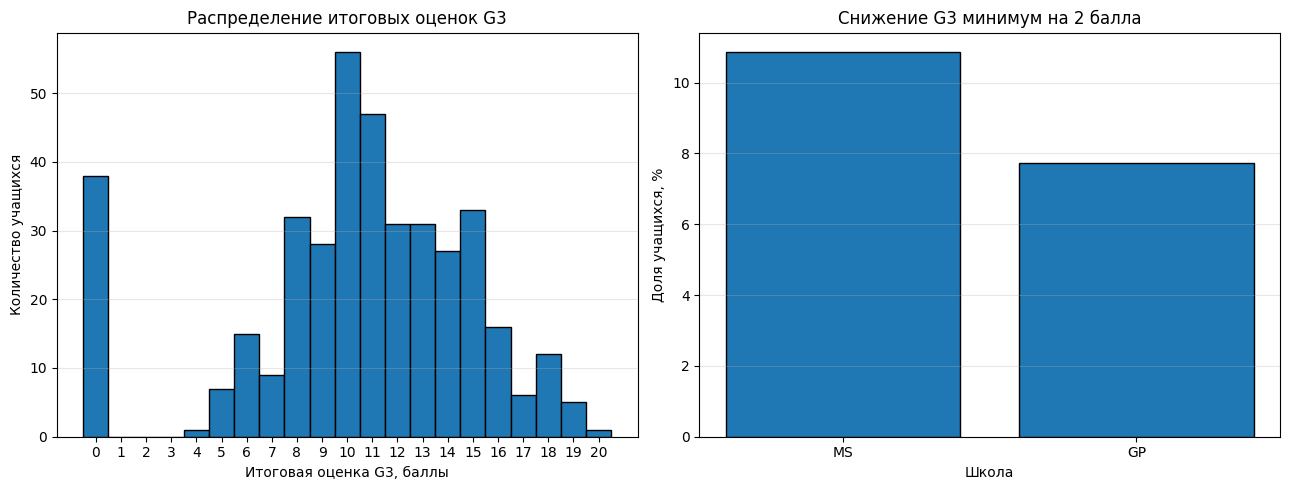

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    data['G3'],
    bins=np.arange(-0.5, 21.5, 1),
    edgecolor='black'
)
axes[0].set_title('Распределение итоговых оценок G3')
axes[0].set_xlabel('Итоговая оценка G3, баллы')
axes[0].set_ylabel('Количество учащихся')
axes[0].set_xticks(range(0, 21))
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(
    school_summary.index,
    school_summary['decrease_share_percent'],
    edgecolor='black'
)
axes[1].set_title('Снижение G3 минимум на 2 балла')
axes[1].set_xlabel('Школа')
axes[1].set_ylabel('Доля учащихся, %')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('risunok_1_matplotlib.png', dpi=300, bbox_inches='tight')
plt.show()

### 3.2. Seaborn: диаграмма рассеяния

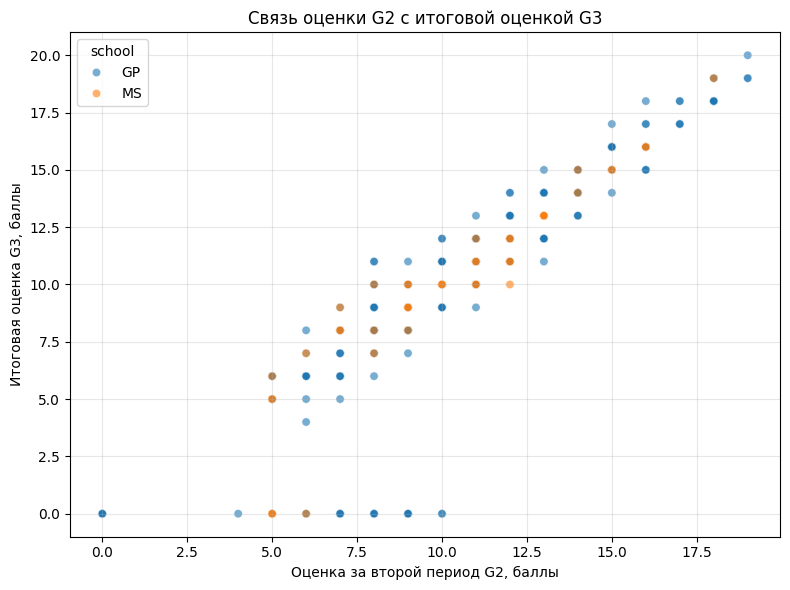

In [9]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=data,
    x='G2',
    y='G3',
    hue='school',
    alpha=0.6
)

plt.title('Связь оценки G2 с итоговой оценкой G3')
plt.xlabel('Оценка за второй период G2, баллы')
plt.ylabel('Итоговая оценка G3, баллы')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('risunok_2_scatterplot.png', dpi=300, bbox_inches='tight')
plt.show()

### 3.3. Seaborn: сравнение распределений по школам

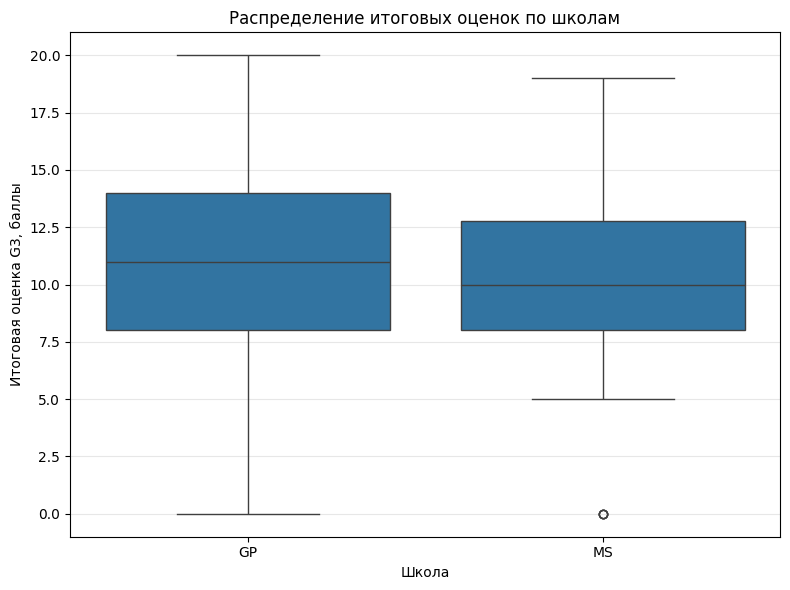

In [10]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=data,
    x='school',
    y='G3'
)

plt.title('Распределение итоговых оценок по школам')
plt.xlabel('Школа')
plt.ylabel('Итоговая оценка G3, баллы')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('risunok_3_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

### 3.4. Изменение параметра графика

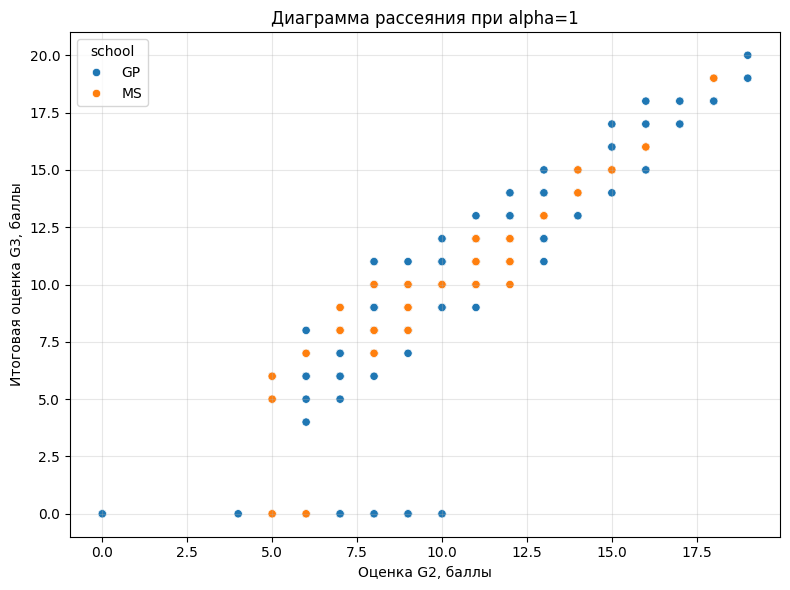

In [11]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=data,
    x='G2',
    y='G3',
    hue='school',
    alpha=1
)

plt.title('Диаграмма рассеяния при alpha=1')
plt.xlabel('Оценка G2, баллы')
plt.ylabel('Итоговая оценка G3, баллы')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

При `alpha=1` точки полностью непрозрачные и сильнее перекрывают друг друга. При `alpha=0.6` точки прозрачнее, поэтому лучше видно скопление наблюдений. Для итогового графика выбран вариант `alpha=0.6`.

## 4. Примените scipy.stats к вопросу своего варианта

### 4.1. Межквартильный размах

In [12]:
iqr_scipy = iqr(data['G3'], rng=(25, 75))
iqr_80 = iqr(data['G3'], rng=(10, 90))

q1 = data['G3'].quantile(0.25)
q3 = data['G3'].quantile(0.75)
iqr_pandas = q3 - q1

print('Первый квартиль Pandas:', q1)
print('Третий квартиль Pandas:', q3)
print('Межквартильный размах SciPy (25–75%):', iqr_scipy)
print('Размах между 10-м и 90-м процентилями:', iqr_80)
print('Разность квартилей Pandas:', iqr_pandas)
print('Результаты совпадают:', np.isclose(iqr_scipy, iqr_pandas))

Первый квартиль Pandas: 8.0
Третий квартиль Pandas: 14.0
Межквартильный размах SciPy (25–75%): 6.0
Размах между 10-м и 90-м процентилями: 10.600000000000023
Разность квартилей Pandas: 6.0
Результаты совпадают: True


### 4.2. Ранговая корреляция Спирмена

Для анализа выбрана корреляция Спирмена, так как нужно проверить направление и силу связи между оценками `G2` и `G3`.

In [13]:
def show_spearman(table, group_name):
    pairs = table[['G2', 'G3']].dropna()

    print('Группа:', group_name)
    print('Количество полных пар:', len(pairs))

    if pairs['G2'].nunique() <= 1 or pairs['G3'].nunique() <= 1:
        print('Коэффициент не определён: один из признаков постоянный.')
    else:
        result = spearmanr(pairs['G2'], pairs['G3'])
        print('Коэффициент Спирмена:', round(result.statistic, 4))
        print('p-value:', result.pvalue)
    print()


show_spearman(data, 'Все учащиеся')

for school_name in data['school'].unique():
    school_data = data[data['school'] == school_name]
    show_spearman(school_data, school_name)

Группа: Все учащиеся
Количество полных пар: 395
Коэффициент Спирмена: 0.9571
p-value: 1.4253415127948729e-213

Группа: GP
Количество полных пар: 349
Коэффициент Спирмена: 0.9568
p-value: 3.626620688483008e-188

Группа: MS
Количество полных пар: 46
Коэффициент Спирмена: 0.9693
p-value: 1.8834857887158932e-28



## 5. Ответьте на вопрос и сдайте работу

In [14]:
total_students = len(data)
total_decreases = int(data['decrease_2plus'].sum())
total_share = data['decrease_2plus'].mean() * 100

print('Всего учащихся:', total_students)
print('Учащихся со снижением минимум на 2 балла:', total_decreases)
print('Доля таких учащихся, %:', round(total_share, 2))

print()
print('Показатели по школам:')
print(school_summary[
    ['students', 'mean_G2', 'mean_G3', 'mean_change',
     'decrease_count', 'decrease_share_percent']
].round(2))

Всего учащихся: 395
Учащихся со снижением минимум на 2 балла: 32
Доля таких учащихся, %: 8.1

Показатели по школам:
        students  mean_G2  mean_G3  mean_change  decrease_count  \
school                                                            
MS            46    10.20     9.85        -0.35               5   
GP           349    10.78    10.49        -0.29              27   

        decrease_share_percent  
school                          
MS                       10.87  
GP                        7.74  


### Ответ на исследовательский вопрос

В ходе анализа выяснилось, что у **32 учащихся из 395** итоговая оценка снизилась минимум на два балла. Это составляет **8,10%** от общего количества учащихся.

В школе GP такое снижение наблюдалось у **7,74%** учеников, а в школе MS — у **10,87%**. Таким образом, в школе MS доля таких случаев оказалась выше.

Средняя оценка в GP снизилась с **10,78 до 10,49**, а в MS — с **10,20 до 9,85**. По одним только средним значениям нельзя определить, у скольких учеников произошло значительное снижение оценки. Поэтому дополнительно была рассчитана доля таких учащихся по каждой школе. Это видно в **таблице групповых показателей** и на **рисунке 1**.

**Ограничение исследования:** в работе учитывались только оценки G2, G3 и школа учащегося. По этим данным нельзя определить причины снижения оценок.

**Использованная функция:** `scipy.stats.iqr` принимает числовые данные и возвращает межквартильный размах. В нашем случае он составил **6 баллов**. Параметр `rng=(25, 75)` задаёт границы процентилей: функция рассчитывает разницу между 75-м и 25-м процентилями. Если указать `rng=(10, 90)`, она рассчитает разницу между 90-м и 10-м процентилями.


## Дополнительное задание

В PyTorch обучите модель прогноза `Y` по `X` и категории. Сравните её с прогнозом по медиане обучающей части на одних и тех же отложенных данных по средней абсолютной ошибке (MAE). Преобразования подберите только на обучающих данных.

In [15]:
import random
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print('Версия PyTorch:', torch.__version__)

Версия PyTorch: 2.14.1+cpu


### Дополнительное задание. Шаг 1. Разделение данных

In [16]:
model_data = data[['G2', 'school', 'G3']].copy()

train_data, test_data = train_test_split(
    model_data,
    test_size=0.2,
    random_state=42,
    stratify=model_data['school']
)

print('Обучающая выборка:', train_data.shape[0])
print('Тестовая выборка:', test_data.shape[0])

print('Школы в обучающей выборке:')
print(train_data['school'].value_counts())

print('Школы в тестовой выборке:')
print(test_data['school'].value_counts())

Обучающая выборка: 316
Тестовая выборка: 79
Школы в обучающей выборке:
school
GP    279
MS     37
Name: count, dtype: int64
Школы в тестовой выборке:
school
GP    70
MS     9
Name: count, dtype: int64


### Дополнительное задание. Шаг 2. Подготовка признаков

In [17]:
g2_mean = train_data['G2'].mean()
g2_std = train_data['G2'].std()

X_train_g2 = ((train_data['G2'] - g2_mean) / g2_std).to_numpy().reshape(-1, 1)
X_test_g2 = ((test_data['G2'] - g2_mean) / g2_std).to_numpy().reshape(-1, 1)

school_categories = sorted(train_data['school'].unique())

school_train = pd.get_dummies(
    pd.Categorical(train_data['school'], categories=school_categories),
    dtype=float
)

school_test = pd.get_dummies(
    pd.Categorical(test_data['school'], categories=school_categories),
    dtype=float
)
school_test = school_test.reindex(columns=school_train.columns, fill_value=0)

X_train = np.concatenate(
    [X_train_g2, school_train.to_numpy()],
    axis=1
).astype('float32')

X_test = np.concatenate(
    [X_test_g2, school_test.to_numpy()],
    axis=1
).astype('float32')

y_train = train_data['G3'].to_numpy(dtype='float32').reshape(-1, 1)
y_test = test_data['G3'].to_numpy(dtype='float32')

print('Размер матрицы обучающих признаков:', X_train.shape)
print('Размер матрицы тестовых признаков:', X_test.shape)
print('Среднее G2 из обучающей выборки:', round(g2_mean, 3))
print('Стандартное отклонение G2 из обучающей выборки:', round(g2_std, 3))

Размер матрицы обучающих признаков: (316, 3)
Размер матрицы тестовых признаков: (79, 3)
Среднее G2 из обучающей выборки: 10.725
Стандартное отклонение G2 из обучающей выборки: 3.827


### Дополнительное задание. Шаг 3. Обучение нейронной сети

In [18]:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

model = nn.Sequential(
    nn.Linear(X_train.shape[1], 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 1)
)

loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 300

for epoch in range(epochs):
    model.train()

    predictions = model(X_train_tensor)
    loss = loss_function(predictions, y_train_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

print('Обучение завершено.')
print('Ошибка на последней эпохе:', round(loss.item(), 4))

Обучение завершено.
Ошибка на последней эпохе: 3.5122


### Дополнительное задание. Шаг 4. Сравнение с базовым прогнозом

In [19]:
model.eval()

with torch.no_grad():
    model_predictions = model(X_test_tensor).numpy().ravel()

baseline_value = np.median(y_train)
baseline_predictions = np.repeat(baseline_value, len(y_test))

mae_model = mean_absolute_error(y_test, model_predictions)
mae_baseline = mean_absolute_error(y_test, baseline_predictions)

comparison = pd.DataFrame({
    'Способ прогноза': ['PyTorch', 'Медиана обучающей выборки'],
    'MAE': [mae_model, mae_baseline]
})

print('Медиана G3 обучающей выборки:', baseline_value)
print(comparison.round(3))

Медиана G3 обучающей выборки: 11.0
             Способ прогноза    MAE
0                    PyTorch  1.100
1  Медиана обучающей выборки  3.076


### Результат дополнительного задания

In [20]:
if mae_model < mae_baseline:
    print('Вывод: модель PyTorch показала меньшую MAE, чем базовый прогноз по медиане.')
    print('Улучшение MAE:', round(mae_baseline - mae_model, 3))
else:
    print('Вывод: базовый прогноз по медиане показал MAE не хуже модели PyTorch.')
    print('Разница MAE:', round(mae_model - mae_baseline, 3))

Вывод: модель PyTorch показала меньшую MAE, чем базовый прогноз по медиане.
Улучшение MAE: 1.976
